Dataset: (569, 30)
Malignant cases: 212
Benign cases: 357
Features: 30
Selected features:
- mean concave points
- worst radius
- worst perimeter
- worst area

Training samples: 426
Testing samples: 143
Classical SVM trained.
Training time: 0.0118 seconds
Test inference time: 0.0039 seconds
              precision    recall  f1-score   support

      Benign       0.91      0.99      0.95        90
   Malignant       0.98      0.83      0.90        53

    accuracy                           0.93       143
   macro avg       0.94      0.91      0.92       143
weighted avg       0.93      0.93      0.93       143



/tmp/ipykernel_1228/2697290311.py:104: DeprecationWarning: The class ``qiskit.circuit.library.data_preparation._zz_feature_map.ZZFeatureMap`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the zz_feature_map function as a replacement. Note that this will no longer return a BlueprintCircuit, but just a plain QuantumCircuit.
  feature_map = ZZFeatureMap(


Training kernel shape: (426, 426)
Test kernel shape: (143, 426)
State preparation time: 0.9308 seconds
Kernel calculation time: 0.0094 seconds
Number of qubits: 4
Feature map depth: 11
Quantum Kernel SVM trained.
SVM fitting time: 0.0200 seconds
Test prediction time: 0.0019 seconds
              precision    recall  f1-score   support

      Benign       0.91      0.97      0.94        90
   Malignant       0.94      0.83      0.88        53

    accuracy                           0.92       143
   macro avg       0.92      0.90      0.91       143
weighted avg       0.92      0.92      0.91       143

                    Accuracy  Precision  Sensitivity  Specificity  F1-score  ROC-AUC  False negatives  False positives
Classical RBF SVM     0.9301     0.9778       0.8302       0.9889     0.898   0.9904                9                1
Quantum Kernel SVM    0.9161     0.9362       0.8302       0.9667     0.880   0.9254                9                3
                        Measureme

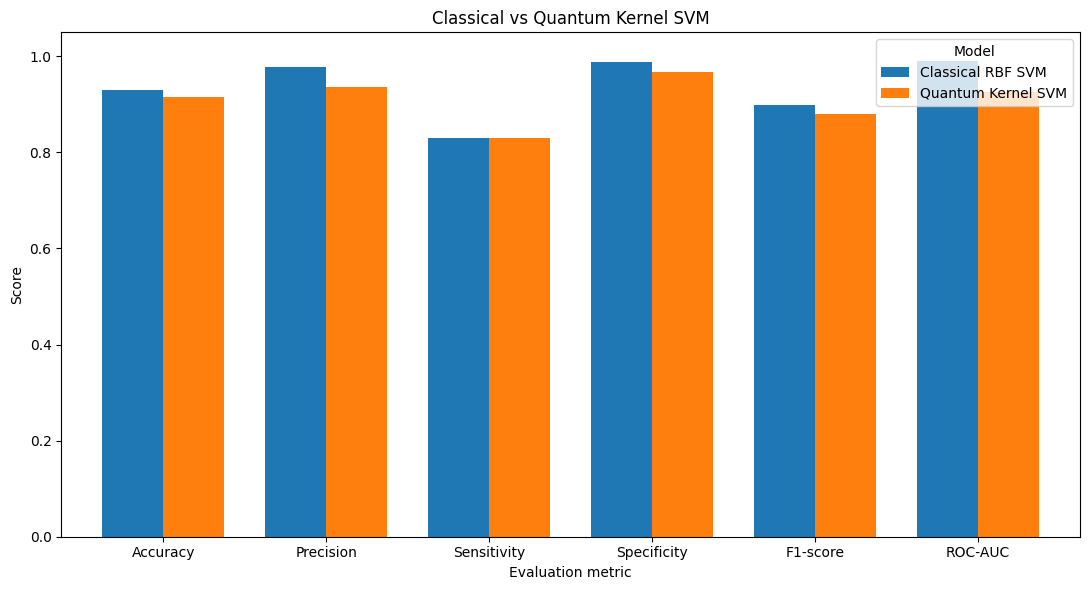

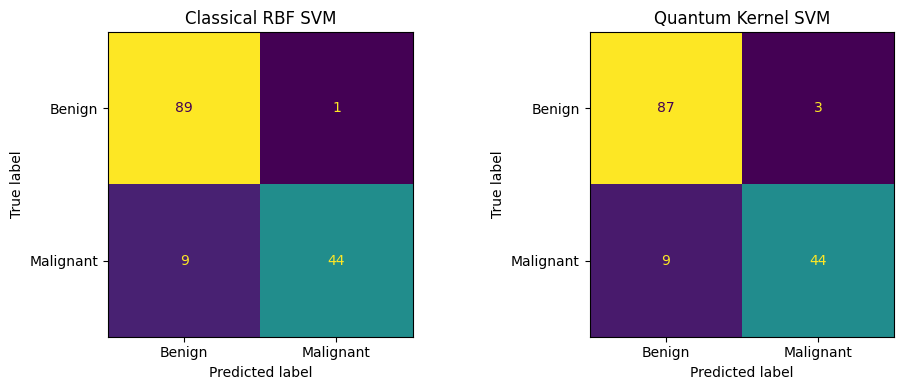

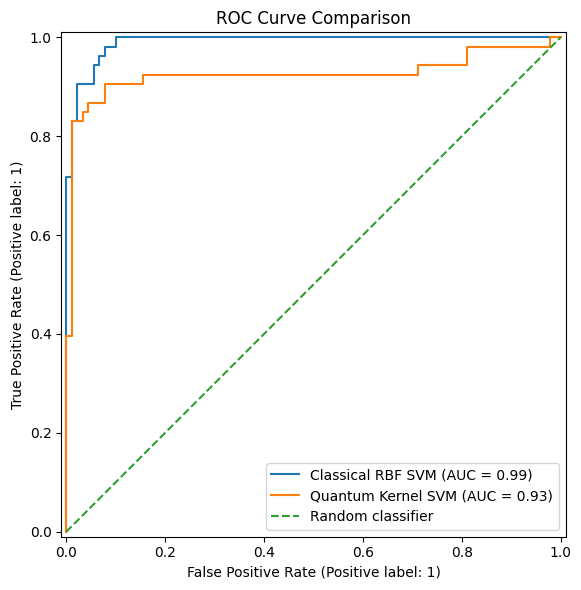

Plots saved in the results/ directory.
Predictions and experiment configuration saved.
Selected features: ['mean concave points', 'worst radius', 'worst perimeter', 'worst area']

QUANTUM MACHINE LEARNING FOR HEALTHCARE
Experiment Summary

Healthcare problem:
Binary classification of malignant versus benign breast masses
using the Wisconsin Diagnostic Breast Cancer dataset.

Dataset:
569 samples, 30 original numerical features.
The models used the same 4 selected features
and the same stratified training/test split.

Selected features:
mean concave points, worst radius, worst perimeter, worst area

Classical model:
RBF Support Vector Machine (SVM), C=1.0, gamma='scale'.

Quantum model:
Four-qubit ZZFeatureMap fidelity kernel with an SVM classifier,
simulated using Qiskit Statevector.

TEST SET RESULTS
                    Accuracy  Precision  Sensitivity  Specificity  F1-score  ROC-AUC  False negatives  False positives
Classical RBF SVM     0.9301     0.9778       0.8302       0.9889   

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:
%pip -q install qiskit

import os
import time
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shutil

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay
)

from qiskit.circuit.library import ZZFeatureMap
from qiskit.quantum_info import Statevector

SEED = 42
np.random.seed(SEED)

os.makedirs("results", exist_ok=True)

data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)

# sklearn encodes malignant=0 and benign=1.
# Reverse the encoding so malignant is the positive class (1).
y = (data.target == 0).astype(int)

print("Dataset:", X.shape)
print("Malignant cases:", int(y.sum()))
print("Benign cases:", int((1-y).sum()))
print("Features:", len(data.feature_names))

X_train_full, X_test_full, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=SEED,
    stratify=y
)

selector = SelectKBest(
    score_func=mutual_info_classif,
    k=4
)

X_train_selected = selector.fit_transform(X_train_full, y_train)
X_test_selected = selector.transform(X_test_full)

selected_features = X.columns[selector.get_support()].tolist()

print("Selected features:")
for feature in selected_features:
    print("-", feature)

print("\nTraining samples:", len(y_train))
print("Testing samples:", len(y_test))

classical_scaler = StandardScaler()

X_train_classical = classical_scaler.fit_transform(X_train_selected)
X_test_classical = classical_scaler.transform(X_test_selected)

classical_model = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale",
    probability=True,
    random_state=SEED
)

start = time.perf_counter()
classical_model.fit(X_train_classical, y_train)
classical_train_time = time.perf_counter() - start

start = time.perf_counter()
classical_pred = classical_model.predict(X_test_classical)
classical_prob = classical_model.predict_proba(X_test_classical)[:, 1]
classical_inference_time = time.perf_counter() - start

print("Classical SVM trained.")
print(f"Training time: {classical_train_time:.4f} seconds")
print(f"Test inference time: {classical_inference_time:.4f} seconds")
print(classification_report(
    y_test, classical_pred,
    target_names=["Benign", "Malignant"],
    zero_division=0
))

# Map the same four selected features to quantum rotation angles.
quantum_scaler = MinMaxScaler(feature_range=(0, np.pi))

X_train_quantum = quantum_scaler.fit_transform(X_train_selected)
X_test_quantum = quantum_scaler.transform(X_test_selected)

# Four qubits, one repetition, linear entanglement.
feature_map = ZZFeatureMap(
    feature_dimension=4,
    reps=1,
    entanglement="linear"
)

def encode_quantum_states(X_angles, circuit):
    """Encode each sample and return its simulated quantum state."""
    parameters = list(circuit.parameters)
    states = []

    for row in X_angles:
        parameter_values = {
            parameter: float(value)
            for parameter, value in zip(parameters, row)
        }

        bound_circuit = circuit.assign_parameters(parameter_values)
        state = Statevector.from_instruction(bound_circuit)
        states.append(state.data)

    return np.asarray(states, dtype=complex)

# State preparation is done once per sample.
start = time.perf_counter()

train_states = encode_quantum_states(
    X_train_quantum, feature_map
)
test_states = encode_quantum_states(
    X_test_quantum, feature_map
)

state_preparation_time = time.perf_counter() - start

# Quantum fidelity kernel: K(x,z) = |<phi(x)|phi(z)>|^2
start = time.perf_counter()

K_train = np.abs(
    train_states.conj() @ train_states.T
) ** 2

K_test = np.abs(
    test_states.conj() @ train_states.T
) ** 2

# Remove tiny floating-point asymmetries from the training matrix.
K_train = (K_train + K_train.T) / 2

quantum_kernel_time = time.perf_counter() - start

print("Training kernel shape:", K_train.shape)
print("Test kernel shape:", K_test.shape)
print(f"State preparation time: {state_preparation_time:.4f} seconds")
print(f"Kernel calculation time: {quantum_kernel_time:.4f} seconds")
print("Number of qubits:", feature_map.num_qubits)
print("Feature map depth:", feature_map.decompose().depth())

quantum_model = SVC(
    kernel="precomputed",
    C=1.0,
    probability=True,
    random_state=SEED
)

start = time.perf_counter()
quantum_model.fit(K_train, y_train)
quantum_train_time = time.perf_counter() - start

start = time.perf_counter()
quantum_pred = quantum_model.predict(K_test)
quantum_prob = quantum_model.predict_proba(K_test)[:, 1]
quantum_inference_time = time.perf_counter() - start

print("Quantum Kernel SVM trained.")
print(f"SVM fitting time: {quantum_train_time:.4f} seconds")
print(f"Test prediction time: {quantum_inference_time:.4f} seconds")
print(classification_report(
    y_test, quantum_pred,
    target_names=["Benign", "Malignant"],
    zero_division=0
))

def calculate_metrics(y_true, y_pred, y_prob):
    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Sensitivity": recall_score(y_true, y_pred, zero_division=0),
        "Specificity": tn / (tn + fp) if (tn + fp) else 0.0,
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "False negatives": int(fn),
        "False positives": int(fp)
    }

classical_metrics = calculate_metrics(
    y_test, classical_pred, classical_prob
)

quantum_metrics = calculate_metrics(
    y_test, quantum_pred, quantum_prob
)

comparison = pd.DataFrame(
    [classical_metrics, quantum_metrics],
    index=["Classical RBF SVM", "Quantum Kernel SVM"]
)

print(comparison.round(4).to_string())

comparison.to_csv("results/model_comparison.csv")

resource_results = {
    "Qubits": int(feature_map.num_qubits),
    "Feature map depth": int(feature_map.decompose().depth()),
    "Training samples": int(len(y_train)),
    "Test samples": int(len(y_test)),
    "Training state preparations": int(len(train_states)),
    "Test state preparations": int(len(test_states)),
    "Training kernel entries": int(K_train.size),
    "Test kernel entries": int(K_test.size),
    "Classical training time (s)": classical_train_time,
    "Classical inference time (s)": classical_inference_time,
    "Quantum state preparation time (s)": state_preparation_time,
    "Quantum kernel calculation time (s)": quantum_kernel_time,
    "Quantum SVM fitting time (s)": quantum_train_time,
    "Quantum prediction time (s)": quantum_inference_time,
    "Quantum total pipeline time (s)": (
        state_preparation_time
        + quantum_kernel_time
        + quantum_train_time
    )
}

resource_df = pd.DataFrame(
    list(resource_results.items()),
    columns=["Measurement", "Value"]
)

print(resource_df.to_string(index=False))
resource_df.to_csv("results/quantum_resources.csv", index=False)

with open("results/quantum_resources.json", "w") as f:
    json.dump(resource_results, f, indent=2)

# 1. Model performance comparison
metric_names = [
    "Accuracy", "Precision", "Sensitivity",
    "Specificity", "F1-score", "ROC-AUC"
]

ax = comparison[metric_names].T.plot(
    kind="bar",
    figsize=(11, 6),
    ylim=(0, 1.05),
    width=0.75
)
ax.set_title("Classical vs Quantum Kernel SVM")
ax.set_ylabel("Score")
ax.set_xlabel("Evaluation metric")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Model")
plt.tight_layout()
plt.savefig("results/performance_comparison.png", dpi=200)
plt.show()

# 2. Confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test, classical_pred,
    labels=[0, 1],
    display_labels=["Benign", "Malignant"],
    ax=axes[0],
    colorbar=False
)
axes[0].set_title("Classical RBF SVM")

ConfusionMatrixDisplay.from_predictions(
    y_test, quantum_pred,
    labels=[0, 1],
    display_labels=["Benign", "Malignant"],
    ax=axes[1],
    colorbar=False
)
axes[1].set_title("Quantum Kernel SVM")

plt.tight_layout()
plt.savefig("results/confusion_matrices.png", dpi=200)
plt.show()

# 3. ROC curves
fig, ax = plt.subplots(figsize=(7, 6))

RocCurveDisplay.from_predictions(
    y_test, classical_prob,
    name="Classical RBF SVM",
    ax=ax
)
RocCurveDisplay.from_predictions(
    y_test, quantum_prob,
    name="Quantum Kernel SVM",
    ax=ax
)

ax.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")
ax.set_title("ROC Curve Comparison")
ax.legend()
plt.tight_layout()
plt.savefig("results/roc_curves.png", dpi=200)
plt.show()

print("Plots saved in the results/ directory.")

predictions = pd.DataFrame({
    "Actual": np.where(np.asarray(y_test) == 1, "Malignant", "Benign"),
    "Classical_prediction": np.where(
        classical_pred == 1, "Malignant", "Benign"
    ),
    "Classical_malignant_probability": classical_prob,
    "Quantum_prediction": np.where(
        quantum_pred == 1, "Malignant", "Benign"
    ),
    "Quantum_malignant_probability": quantum_prob
})

predictions.to_csv("results/test_predictions.csv", index=False)

config = {
    "dataset": "Wisconsin Diagnostic Breast Cancer",
    "random_seed": SEED,
    "test_size": 0.25,
    "feature_selection": "SelectKBest(mutual_info_classif, k=4)",
    "selected_features": selected_features,
    "classical_model": "SVC(kernel=\'rbf\', C=1.0, gamma=\'scale\')",
    "quantum_model": "Quantum fidelity kernel SVM",
    "quantum_feature_map": "ZZFeatureMap",
    "qubits": 4,
    "feature_map_repetitions": 1,
    "quantum_backend": "Qiskit Statevector simulator",
    "positive_class": "Malignant"
}

with open("results/experiment_config.json", "w") as f:
    json.dump(config, f, indent=2)

print("Predictions and experiment configuration saved.")
print("Selected features:", selected_features)

# Build a results-based summary.
best_model = comparison["ROC-AUC"].idxmax()
roc_gap = (
    comparison.loc["Quantum Kernel SVM", "ROC-AUC"]
    - comparison.loc["Classical RBF SVM", "ROC-AUC"]
)

summary = f"""
QUANTUM MACHINE LEARNING FOR HEALTHCARE
Experiment Summary

Healthcare problem:
Binary classification of malignant versus benign breast masses
using the Wisconsin Diagnostic Breast Cancer dataset.

Dataset:
{len(X)} samples, 30 original numerical features.
The models used the same {len(selected_features)} selected features
and the same stratified training/test split.

Selected features:
{", ".join(selected_features)}

Classical model:
RBF Support Vector Machine (SVM), C=1.0, gamma=\'scale\'.

Quantum model:
Four-qubit ZZFeatureMap fidelity kernel with an SVM classifier,
simulated using Qiskit Statevector.

TEST SET RESULTS
{comparison.round(4).to_string()}

ROC-AUC difference (quantum minus classical): {roc_gap:.4f}
Model with higher test ROC-AUC: {best_model}

COMPUTATIONAL COST
Classical training: {classical_train_time:.4f} seconds
Classical inference: {classical_inference_time:.4f} seconds
Quantum state preparation: {state_preparation_time:.4f} seconds
Quantum kernel construction: {quantum_kernel_time:.4f} seconds
Quantum SVM fitting: {quantum_train_time:.4f} seconds
Quantum prediction: {quantum_inference_time:.4f} seconds

INTERPRETATION
The measured ROC-AUC difference is descriptive of this held-out
test split and does not establish statistical significance or
generalization to other populations.

The quantum kernel was evaluated using a classical statevector
simulator. Therefore, these results do not demonstrate quantum
speedup or a hardware-level quantum advantage.

This is a research prototype, not a clinical diagnostic system.
Further validation, uncertainty analysis, and independent external
testing would be necessary before considering clinical use.
"""

with open("results/experiment_summary.txt", "w") as f:
    f.write(summary)

print(summary)

archive_path = shutil.make_archive(
    "quantum_healthcare_submission",
    "zip",
    root_dir=".",
    base_dir="results"
)

print("\nCreated:", archive_path)

try:
    from google.colab import files
    files.download(archive_path)
except ImportError:
    print("ZIP is saved in the current working directory.")
